In [1]:
# libraries for data manipulation
import numpy as np
import pandas as pd
from sklearn import datasets

# libraries for visualization 
from plotnine import *
import matplotlib.pyplot as plt

# helper functions
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

# classifiers 
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('code_1_data.csv') # loads dataset to pandas

print(df.head()) # prints first 5 rows of data 
print(df.info()) # checks data types and null values

df = df.dropna() # drop missing values

X = df.drop(columns = ['Y']) # separates independent/dependent variables
y = df['Y']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42, stratify= y) # 80/20 train/test split. 


         X1        X2        X3        X4        X5        X6        X7  \
0 -0.604285 -0.610629  0.026014  0.019710  0.406532  0.678796  0.524360   
1 -0.111772 -1.125178  0.744157  0.078315  0.088176  0.891009  0.018460   
2 -0.916802  1.965494  0.150022  0.388770  0.179276  0.064449  0.159279   
3 -0.280479  0.920669  0.208949  0.940153  0.854437  0.688172  0.365126   
4  1.856025  1.043214  0.167088  0.207002  0.979049  0.641019  0.628764   

         X8  Y  
0  0.404739  B  
1  0.536511  B  
2  0.951204  B  
3  0.985259  A  
4  0.045912  B  
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      1000 non-null   float64
 1   X2      1000 non-null   float64
 2   X3      1000 non-null   float64
 3   X4      1000 non-null   float64
 4   X5      1000 non-null   float64
 5   X6      1000 non-null   float64
 6   X7      1000 non-null   float64
 7   X8      1000 no

Best Parameters for SVM: {'svc__C': 50, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Train Accuracy:  0.7913
Test Accuracy:  0.7450
Test ROC AUC Score:  0.8025


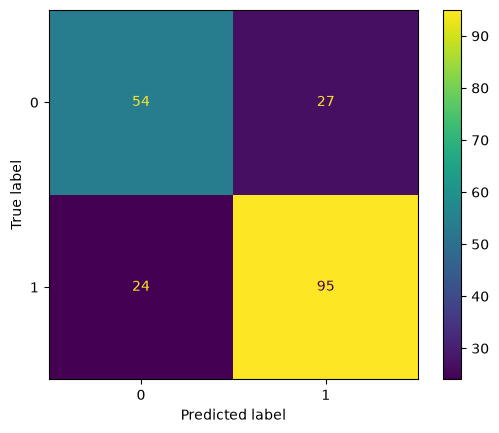

In [3]:
pipe_svm = Pipeline ([ # pipeline that scales features and then fits SVM classifier
    ('scaler', StandardScaler()),
    ('svc', SVC(probability= True, random_state= 42))
])

parameter_grid_svm = { # range of hyperparameters that gets tested during grid search
    'svc__kernel': ['linear', 'rbf'],
    'svc__C': [0.001, 0.01, 1, 5, 25, 50],
    'svc__gamma': [0.001, 0.01, 0.1, 0.5, 1, 2, 5]
}

grid_svm = GridSearchCV(pipe_svm, parameter_grid_svm, cv= 5, scoring= 'accuracy') # cross validation grid search
grid_svm.fit(X_train, y_train)

svm_best = grid_svm.best_estimator_ # save and print best parameters
print('Best Parameters for SVM:', grid_svm.best_params_)

y_train_predict = svm_best.predict(X_train) # preditct train and test sets
y_test_predict = svm_best.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_predict) # calculate and print train and test accuracy
test_accuracy = accuracy_score(y_test, y_test_predict)
print(f"Train Accuracy: {train_accuracy: .4f}")
print(f"Test Accuracy: {test_accuracy: .4f}")

roc_auc = roc_auc_score(y_test, svm_best.decision_function(X_test)) # calculate and print ROC AUC Score
print(f"Test ROC AUC Score: {roc_auc: .4f}")

cm = confusion_matrix(y_test, y_test_predict) # plot confusion matrix for test results
cm_display = ConfusionMatrixDisplay(confusion_matrix= cm)
cm_display.plot()
plt.show()

train Accuracy:  0.7688
Test Accuracy:  0.7250
Test ROC AUC Score:  0.8055


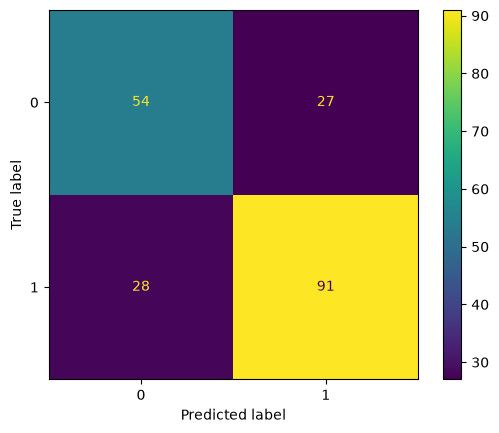

In [4]:
pipe_logreg = Pipeline([ # pipeline that scales features and then fits logistic regression model 
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(random_state= 42))
])

pipe_logreg.fit(X_train, y_train) # trains the model

y_train_predict = pipe_logreg.predict(X_train) # predict train and test sets  
y_test_predict = pipe_logreg.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_predict) # calculate and print train and test accuracy 
test_accuracy = accuracy_score(y_test, y_test_predict)
print(f"train Accuracy: {train_accuracy: .4f}")
print(f"Test Accuracy: {test_accuracy: .4f}")

roc_auc = roc_auc_score(y_test, pipe_logreg.predict_proba(X_test)[:, 1]) # calculate and print ROC AUC score
print(f"Test ROC AUC Score: {roc_auc: .4f}")

cm = confusion_matrix(y_test, y_test_predict) # plot confusion matrix
cm_display = ConfusionMatrixDisplay(confusion_matrix= cm)
cm_display.plot()
plt.show()

Best kNN Parameters:  {'knn__n_neighbors': 29}
Train Accuracy:  0.7600
Test Accuracy:  0.7250
Test ROC AUC Score:  0.7987


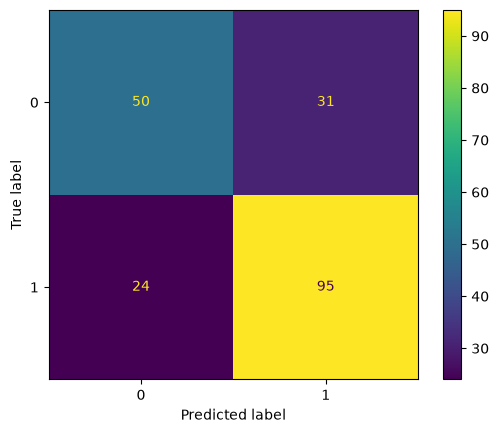

In [5]:
pipe_knn = Pipeline ([ # pipeline that scales features and then fits knn classifier 
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

parameter_grid_knn = {'knn__n_neighbors': list(range(1, 31))} # test k values from 1 to 30 

grid_knn = GridSearchCV(pipe_knn, parameter_grid_knn, cv= 5, scoring= 'accuracy') # cross validation grid search 
grid_knn.fit(X_train, y_train)

knn_best = grid_knn.best_estimator_ # save and print best parameters 
print("Best kNN Parameters: ", grid_knn.best_params_)

y_train_predict = knn_best.predict(X_train) # predicts traim and test sets 
y_test_predict = knn_best.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_predict) # calculate and print trsin and test accuracy 
test_accuracy = accuracy_score(y_test, y_test_predict)
print(f"Train Accuracy: {train_accuracy: .4f}")
print(f"Test Accuracy: {test_accuracy: .4f}")

roc_auc = roc_auc_score(y_test, knn_best.predict_proba(X_test)[:, 1]) # calculate and print ROC AUC score
print(f"Test ROC AUC Score: {roc_auc: .4f}")

cm = confusion_matrix(y_test, y_test_predict) # plot confusion matric
cm_display = ConfusionMatrixDisplay(confusion_matrix= cm)
cm_display.plot()
plt.show()